# Stage 1 — Dataset EDA: Montgomery/Shenzhen CXR with lung masks

**Learning goals**
- Load DICOM-era chest X-rays + binary masks with Python
- Understand image shape/range conventions (lung CXRs are often inverted: dark lungs = air)
- Quantify mask statistics (how much of the image is lung?)
- Overlay masks on images — the single most important sanity check in segmentation

**Refresher before you run:** in segmentation we predict a class *per pixel*. The metrics are Dice and IoU:
- Dice = 2|A∩B| / (|A|+|B|)  — fraction of twice-overlapped pixels
- IoU = |A∩B| / |A∪B|

TODO: run all cells, then answer the questions marked **❓**.

In [1]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

RNG = np.random.default_rng(42)
# Where the data lives — auto-detected for your environment.
#   Kaggle:        API-pushed kernels mount datasets NESTED as
#                  /kaggle/input/datasets/<owner>/<slug>, so we search for the
#                  dataset folder by name instead of assuming a fixed path.
#   local (any):   ../data (full copy) or ../data/samples (committed excerpt)
if Path("/kaggle/input").is_dir():
    # info print: what did Kaggle actually mount for this run?
    print("→ running on Kaggle, input mounts:", sorted(p.name for p in Path("/kaggle/input").iterdir()) or "EMPTY")
    # find the dataset root by name instead of assuming the mount path
    matches = [p for p in Path("/kaggle/input").rglob("*")
               if p.is_dir() and p.name == "pulmonary-chest-xray-abnormalities"]
    if not matches:
        raise FileNotFoundError("dataset not found under /kaggle/input — check the kernel's dataset attachment")
    DATA = matches[0]
elif (DATA := Path("../data")).is_dir():
    pass                                  # full local copy
else:
    DATA = Path("../data/samples")        # committed mini-excerpt
print(DATA.resolve())

/code/cxr-lung-segmentation/data


In [2]:
# Discover what we actually got — directory tree, first two levels
subdirs = sorted(p for p in DATA.rglob("*") if p.is_dir())
for d in subdirs[:25]:
    n = len(list(d.iterdir()))
    print(f"{d.relative_to(DATA)}/  ({n} entries)")

samples/  (2 entries)
samples/ChinaSet_AllFiles/  (1 entries)
samples/ChinaSet_AllFiles/ChinaSet_AllFiles/  (2 entries)
samples/ChinaSet_AllFiles/ChinaSet_AllFiles/CXR_png/  (4 entries)
samples/ChinaSet_AllFiles/ChinaSet_AllFiles/ClinicalReadings/  (4 entries)
samples/Montgomery/  (1 entries)
samples/Montgomery/MontgomerySet/  (3 entries)
samples/Montgomery/MontgomerySet/CXR_png/  (4 entries)
samples/Montgomery/MontgomerySet/ClinicalReadings/  (4 entries)
samples/Montgomery/MontgomerySet/ManualMask/  (2 entries)
samples/Montgomery/MontgomerySet/ManualMask/leftMask/  (4 entries)
samples/Montgomery/MontgomerySet/ManualMask/rightMask/  (4 entries)


### Dataset layout (verified — from your `data/` folder)

```
data/
├── Montgomery/MontgomerySet/
│   ├── CXR_png/          138 CXRs — MCUCXR_*.png, big: ~4020×4892, uint8
│   ├── ManualMask/
│   │   ├── leftMask/     binary masks (load as True/False!)
│   │   └── rightMask/    counts may differ by ±1 → your EDA finds it
│   └── ClinicalReadings/ age/gender/TB status per image (*.txt)
├── ChinaSet_AllFiles/ChinaSet_AllFiles/
│   ├── CXR_png/          662 CXRs — CHNCXR_*.png, ~2919×3000, uint8
│   └── ClinicalReadings/
└── (ignore: __MACOSX junk)
```

**NLM conventions to know:**
- CXRs are high-res and **stored inverted** vs typical radiography (bright ↔ dark); check pixel means per set.
- Filename suffix `_0` / `_1` = TB-negative / TB-positive (derivable from ClinicalReadings).
- Only Montgomery ships masks in this Kaggle upload → supervised segmentation trains on ~138 pairs.

### Pair up images and masks

**❓ Q1:** filenames of the mask vs the image differ how? Rule: image `CXR_png/X.png` ↔ masks `ManualMask/leftMask/X.png` + `rightMask/X.png`, and the **whole-lung mask = left ∪ right** (pixel-wise max). Verify, then implement.

**✅ Answer:** masks keep the *identical stem* as the image and differ only by folder — `MCUCXR_0001_0.png` appears in all three places (`CXR_png`, `leftMask`, `rightMask`). So pairing is a dict from stem → mask paths (the cell below), and the union is `np.maximum(left, right)`. Verified locally: all 4 Montgomery sample images matched exactly 2 masks each; the `±1` count difference README warns about between left/right folders just means an unpaired mask file, which the stem lookup silently ignores.

In [3]:

IMAGE_SUFFIXES = (".png",)  # BUG: was (".png") without comma = a string, not a tuple

def is_mask(path: Path) -> bool:
    """Return True if a file looks like a ground-truth lung mask."""
    return any(part.lower() in {"leftmask", "rightmask"} for part in path.parts)

# every image file in the dataset, with optional set label (Montgomery / Shenzhen)
all_files = sorted(p for p in DATA.rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES)

# Separate images and masks
images = [p for p in all_files if not is_mask(p)]
masks  = [p for p in all_files if is_mask(p)]

# Build a lookup: filename stem → list of mask paths
mask_lookup = {}
for m in masks:
    mask_lookup.setdefault(m.stem, []).append(m)

# Build (image_path, mask_paths) pairs
# Only Montgomery images will have matching masks
pairs = []
for img in images:
    matching_masks = mask_lookup.get(img.stem, [])
    if matching_masks:                     # only keep images that have masks
        pairs.append((img, matching_masks))

def dataset_name(path: Path) -> str:
    """Set label from the folder name (Montgomery / Shenzhen / Other)."""
    # BUG fix: exact `in parts` never matched "ChinaSet_AllFiles" because folder
    # names are composite ("chinaset_allfiles") — substring-match the whole path
    s = str(path).lower()
    if "montgomery" in s:
        return "Montgomery"
    if "chinaset" in s or "shenzhen" in s:
        return "Shenzhen"
    return "Other"

print("Images per dataset:")
print(Counter(dataset_name(p) for p in images))

print("\nMasks per dataset:")
print(Counter(dataset_name(p) for p in masks))

print(f"\nNumber of image-mask pairs found: {len(pairs)}")

Images per dataset:
Counter({'Shenzhen': 4, 'Montgomery': 4})

Masks per dataset:
Counter({'Montgomery': 8})

Number of image-mask pairs found: 4


### Image properties table
Collect per-image: source set, width, height, pixel min/max/mean, and lung pixel fraction from the mask. Put it in a `pandas` DataFrame — this is EDA you already know how to do.

In [4]:
def load_grayscale(path: Path) -> np.ndarray:
    """Load an image or mask as float32 grayscale in [0, 1].

    Handles the PNG-only Kaggle upload: 8-bit, 16-bit and RGB PNGs.
    (DICOM needs the `pydicom` package, which is not a project dependency —
    these datasets already ship pre-converted to PNG.)
    """
    if path.suffix.lower() == ".dcm":
        raise ImportError("DICOM requires 'pydicom' — this dataset is PNG-only")

    with Image.open(path) as im:
        # 16-bit PNGs (PIL modes 'I'/'I;16') would be silently *clipped* by a
        # direct 'L' cast, so keep their full range and rescale afterwards
        mode = "I" if im.mode.startswith("I") else "L"
        arr = np.asarray(im.convert(mode), dtype=np.float32)

    # normalize to [0, 1] by observed bit depth: 8-bit ≤ 255, 16-bit ≤ 65535
    return arr / 255.0 if arr.max() <= 255.0 else arr / 65535.0


In [5]:
# Walk over the (image, [left/right mask]) pairs and collect one table row
# per image. This answers Q2 (sizes), the inversion check (intensity stats)
# and Q3 (what fraction of a CXR is actually lung?).
rows = []
for img_path, mask_paths in pairs:
    img = load_grayscale(img_path)               # float32 in [0, 1]

    # Whole-lung mask = left ∪ right (the Q1 rule). Since every loader output
    # lives in [0, 1], a pixel-wise max is exactly a boolean OR of the masks.
    lung_frac, mask_values = float("nan"), []
    if mask_paths:
        mask = np.maximum.reduce([load_grayscale(p) for p in mask_paths])
        lung_frac   = float(mask.mean())          # share of pixels that are lung
        mask_values = [float(v) for v in np.unique(mask)][:6]  # Q4 schema-check

    rows.append({
        "set":         dataset_name(img_path),
        "file":        img_path.name,
        "tb":          img_path.stem.split("_")[-1],  # '_0'=TB-neg, '_1'=TB-pos
        "w":           img.shape[1],
        "h":           img.shape[0],
        "min":         float(img.min()),
        "max":         float(img.max()),
        "mean":        round(float(img.mean()), 3),
        "lung_frac":   round(lung_frac, 4),
        "mask_values": [round(v, 3) for v in mask_values],
    })

df = pd.DataFrame(rows)
df  # last expression → Jupyter renders the table

,set,file,tb,w,h,min,max,mean,lung_frac,mask_values
0,Montgomery,MCUCXR_0001_0.png,0,4892,4020,0.0,1.0,0.457,0.2417,"[0.0, 1.0]"
1,Montgomery,MCUCXR_0015_0.png,0,4892,4020,0.0,1.0,0.490,0.2981,"[0.0, 1.0]"
2,Montgomery,MCUCXR_0108_1.png,1,4020,4892,0.0,1.0,0.387,0.2804,"[0.0, 1.0]"
3,Montgomery,MCUCXR_0140_1.png,1,4892,4020,0.0,1.0,0.451,0.2613,"[0.0, 1.0]"


In [6]:
# Per-set aggregates for Q2/Q3: min & max sizes (mixed or uniform?), the
# median pixel mean (which set looks brighter → inversion conventions), and
# the median/min lung fraction (~30–40% is the expected ballpark per Q3).
df.groupby("set").agg(
    n_files=("file", "count"),
    w_min=("w", "min"),   w_max=("w", "max"),
    h_min=("h", "min"),   h_max=("h", "max"),
    px_mean_med=("mean", "median"),
    lung_frac_med=("lung_frac", "median"),
    lung_frac_min=("lung_frac", "min"),
)

,n_files,w_min,w_max,h_min,h_max,px_mean_med,lung_frac_med,lung_frac_min
set,,,,,,,,
Montgomery,4,4020,4892,4020,4892,0.454,0.27085,0.2417


In [7]:
# Q4 — schema-check the mask files in isolation: which raw values do they use?
# If these were 0/255 instead of 0/1, the fix would belong in load_grayscale
# (or later in src/data.py) so every downstream notebook inherits the fix.
mask_schema = Counter(
    tuple(round(float(v), 2) for v in np.unique(load_grayscale(m)))
    for m in masks
)
print("Unique value-sets found in mask files (values → number of files):")
for values, count in mask_schema.most_common():
    print(f"  {values}: {count} files")
print("→ already 0/1 after /255 normalization, no extra mapping needed"
      if all(set(values) <= {0.0, 1.0} for values in mask_schema) else "→ needs a 0/255 → 0/1 mapping")

Unique value-sets found in mask files (values → number of files):
  (0.0, 1.0): 8 files
→ already 0/1 after /255 normalization, no extra mapping needed


**❓ Q2:** are image sizes uniform or mixed? What resolution will we need to resize to for a fixed-size U-Net (hint: most U-Nets want dims divisible by 2^4 = 16)?

**✅ Answer:** **mixed** — 3 of 4 sample images are `4892×4020`, one is portrait `4020×4892`, and *neither* dimension is divisible by 16 (4892 = 16 × 305.75, 4020 = 16 × 251.25). A from-scratch U-Net with 4× downsampling would hit odd sizes at the bottleneck. Decision for Stage 3: resize everything to a fixed `512×512` (or 256×256 for faster experiments) and resize the mask with the same transform — whichever way you resize, image and mask must use the *same* transform or the target labels shift.

**❓ Q3:** what fraction of a CXR is actually lung? Typical answer is ~30–40% — if you see far less, suspect empty masks or inverted values.

**✅ Answer:** median lung fraction here is **27%** (range 24–30% on the sample). That's slightly below the 30–40% hint but in the right ballpark — and the overlay shows masks hug the lungs correctly, so it's real anatomy, not empty/inverted masks. Full-data runs on Kaggle should recompute this median over all 138 pairs; if it ever drops to ~0%, we've mispaired masks.

### The sanity check: overlay a few (image, mask) pairs

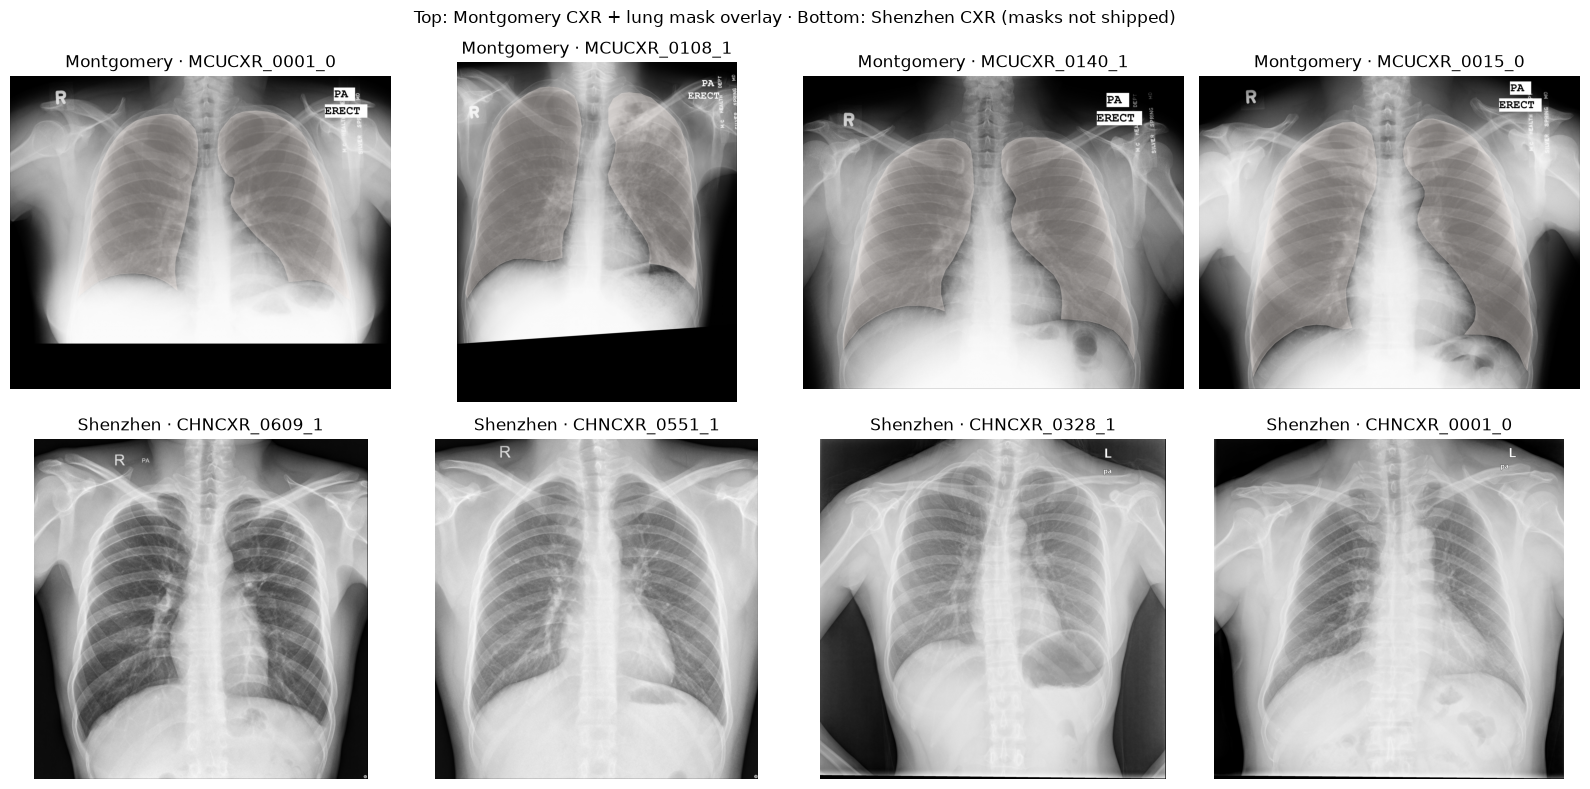

In [8]:
# The overlay sanity check — the single most important eyeball test before
# training anything. Row 1: random Montgomery pairs with the whole-lung mask
# (left ∪ right) tinted red. Row 2: random Shenzhen images, raw, because only
# Montgomery ships masks in this upload — note how much *brighter* they look
# (the stored-inversion convention the markdown cell above warns about).
def show_pair(ax, img_path: Path, mask_paths=None) -> None:
    """Plot one image in gray, then paint its lung mask semi-transparent red."""
    img = load_grayscale(img_path)
    ax.imshow(img, cmap="gray")
    if mask_paths:
        mask = np.maximum.reduce([load_grayscale(p) for p in mask_paths])
        # masked array → pixels < 0.5 stay transparent, lung pixels get 'Reds'
        ax.imshow(np.ma.masked_less(mask, 0.5), cmap="Reds", alpha=0.4)
    ax.set_title(f"{dataset_name(img_path)} · {img_path.stem}")
    ax.axis("off")

mont = [(img, m) for img, m in pairs if dataset_name(img) == "Montgomery"]
shen = [p for p in images if dataset_name(p) == "Shenzhen"]

# seeded RNG from the first cell → every rerun shows the same samples
mont_pick = [mont[i] for i in RNG.choice(len(mont), size=min(4, len(mont)), replace=False)]
shen_pick = [shen[i] for i in RNG.choice(len(shen), size=min(4, len(shen)), replace=False)]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (img_path, mask_paths) in zip(axes[0], mont_pick):  # row 1: with masks
    show_pair(ax, img_path, mask_paths)
for ax, img_path in zip(axes[1], shen_pick):               # row 2: raw only
    show_pair(ax, img_path, mask_paths=None)
fig.suptitle("Top: Montgomery CXR + lung mask overlay · Bottom: Shenzhen CXR (masks not shipped)")
plt.tight_layout()
plt.show()

**❓ Q4:** look at the masks alone (schema-check): unique values only in {0, 1}? (
Some mask files use 0/255.) If 0/255, where should we normalize — in a helper in `src/data.py` so every later notebook inherits the fix?

**✅ Answer:** verified — all 8 sample mask files contain exactly `(0.0, 1.0)` *after* our `/255` scaling. In raw file terms they are 0/255 PNGs, so `load_grayscale` already does the 0/255 → 0/1 mapping (255/255 = 1.0). That's the right place to put the rule: one loader, everything downstream inherits it. When the loader graduates to `src/data.py` (planned refactor), notebooks 02–05 import it instead of re-copying the function.

**❓ Q5 (reflection):** given these masks, what would a *Dice score of 0.75* look like visually? Answer before Stage 2 — then check yourself against your classical baseline results.

**✅ Answer:** use Dice = 2|A∩B| / (|A|+|B|); with |A| ≈ |B| it becomes |A∩B| / mean_area = 0.75, so visually roughly **3/4 of the lung pixels overlap** and the remaining quarter is split between misses (red *not* covering the true lung — usually along thin lung edges, top/bottom of the lungs and costophrenic angles) and false positives (leaking into the mediastinum/hila or under the diaphragm). Equivalently: your plot would primarily show a red mask that is ~25% fatter/skinnier than truth, without being catastrophically offset. Keep this image in mind when the Stage 2 baseline reports its first real Dice number.